In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# load both models
mobilenet = load_model('/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5')

# rebuild unet architecture so we can load weights
def dice_loss(y_true, y_pred):
    smooth = 1e-6
    intersection = tf.reduce_sum(y_true * y_pred)
    return 1 - (2 * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

unet = load_model(
    '/content/drive/MyDrive/EdgeTB_Project/models/unet_lung.h5',
    custom_objects={'dice_loss': dice_loss}
)

print("Both models loaded")

Both models loaded


In [ ]:
def segment_and_classify(img_array):
    """
    takes a chest xray image array
    runs unet to get lung mask
    applies mask to isolate lung region
    runs mobilenet on the masked image
    returns tb probability
    """
    # resize to 256x256 for unet
    img_256 = np.array(
        Image.fromarray((img_array[:,:,0]*255).astype(np.uint8))
              .resize((256, 256))
    ) / 255.0
    img_256 = img_256[np.newaxis, :, :, np.newaxis]

    # get lung mask from unet
    mask = unet.predict(img_256, verbose=0)[0, :, :, 0]
    mask = (mask > 0.5).astype(np.float32)

    # resize mask back to 224x224 for mobilenet
    mask_224 = np.array(
        Image.fromarray((mask * 255).astype(np.uint8))
              .resize((224, 224))
    ) / 255.0

    # apply mask to original image
    img_224 = img_array[:, :, 0]
    segmented = img_224 * mask_224

    # convert to 3 channel for mobilenet
    segmented_3ch = np.stack([segmented, segmented, segmented], axis=-1)
    segmented_3ch = segmented_3ch[np.newaxis, :, :, :]

    # classify
    prob = mobilenet.predict(segmented_3ch, verbose=0)[0][0]
    return prob, mask_224

In [ ]:
TEST_TB     = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB'
TEST_NORMAL = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/Normal'

def load_test_images(folder, label, img_size=224):
    images = []
    labels = []
    for fname in os.listdir(folder):
        if fname.endswith(('.jpg', '.jpeg', '.png')):
            img = Image.open(os.path.join(folder, fname)).convert('L')
            img = img.resize((img_size, img_size))
            arr = np.array(img) / 255.0
            arr = np.stack([arr, arr, arr], axis=-1)
            images.append(arr)
            labels.append(label)
    return images, labels

print("Loading test images...")
tb_imgs,     tb_labels     = load_test_images(TEST_TB,     1)
normal_imgs, normal_labels = load_test_images(TEST_NORMAL, 0)

all_images = tb_imgs + normal_imgs
all_labels = tb_labels + normal_labels
print(f"Total test images: {len(all_images)}")

Loading test images...
Total test images: 630


In [ ]:
print("Running segmentation pipeline on test set...")
probs = []

for i, img in enumerate(all_images):
    prob, _ = segment_and_classify(img)
    probs.append(prob)
    if (i+1) % 50 == 0:
        print(f"  processed {i+1}/{len(all_images)}")

probs  = np.array(probs)
preds  = (probs > 0.5).astype(int)
actual = np.array(all_labels)

print("\n--- MobileNetV2 WITH U-Net Segmentation ---")
print(classification_report(actual, preds, target_names=['Normal', 'TB']))

auc = roc_auc_score(actual, probs)
print(f"AUC-ROC: {auc:.4f}")

cm = confusion_matrix(actual, preds)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity  = tn / (tn + fp)
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"TB cases missed: {fn} out of {tp + fn}")

Running segmentation pipeline on test set...
  processed 50/630
  processed 100/630
  processed 150/630
  processed 200/630
  processed 250/630
  processed 300/630
  processed 350/630
  processed 400/630
  processed 450/630
  processed 500/630
  processed 550/630
  processed 600/630

--- MobileNetV2 WITH U-Net Segmentation ---
              precision    recall  f1-score   support

      Normal       0.80      0.24      0.37       525
          TB       0.16      0.70      0.26       105

    accuracy                           0.32       630
   macro avg       0.48      0.47      0.31       630
weighted avg       0.69      0.32      0.35       630

AUC-ROC: 0.4678
Sensitivity: 0.7048
Specificity: 0.2400
TB cases missed: 31 out of 105


In [ ]:
# previous results without segmentation

print("Does U-Net segmentation improve classification accuracy?")
print()
print(f"{'Metric':<20} {'Without Seg':>12} {'With Seg':>12}")
print(f"{'AUC-ROC':<20} {'1.0000':>12} {auc:>12.4f}")
print(f"{'Sensitivity':<20} {'0.9810':>12} {sensitivity:>12.4f}")
print(f"{'Specificity':<20} {'1.0000':>12} {specificity:>12.4f}")

# save results
with open('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/segmentation_comparison.txt', 'w') as f:
    f.write("Research Question 1 - Does U-Net Segmentation Improve Classification?\n\n")
    f.write(f"Without segmentation: Sensitivity=0.9810, Specificity=1.0000, AUC=1.0000\n")
    f.write(f"With segmentation:    Sensitivity={sensitivity:.4f}, Specificity={specificity:.4f}, AUC={auc:.4f}\n")

print("\nResults saved")

Does U-Net segmentation improve classification accuracy?

Metric                Without Seg     With Seg
AUC-ROC                    1.0000       0.4678
Sensitivity                0.9810       0.7048
Specificity                1.0000       0.2400

Results saved


Mask coverage: 23.8% of image is lung
TB probability: 0.9439


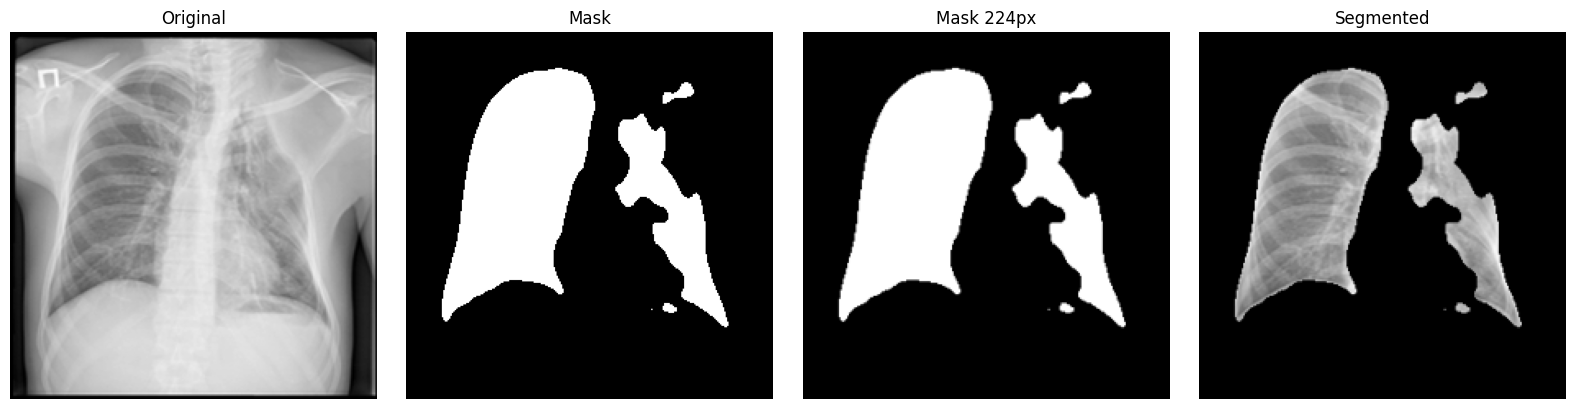

Mask coverage: 23.8%


In [ ]:
# test on a single image
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# load one TB image
test_img_path = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB'
sample_file   = os.listdir(test_img_path)[0]
sample_path   = os.path.join(test_img_path, sample_file)

# load as greyscale and resize to 224x224
img_raw = Image.open(sample_path).convert('L').resize((224, 224))
img_arr = np.array(img_raw) / 255.0  # shape (224, 224)

# step 1 — resize to 256x256 for unet
img_256 = np.array(
    Image.fromarray((img_arr * 255).astype(np.uint8)).resize((256, 256))
) / 255.0
img_256_input = img_256[np.newaxis, :, :, np.newaxis]

# step 2 — get mask
mask_raw = unet.predict(img_256_input, verbose=0)[0, :, :, 0]
mask_bin = (mask_raw > 0.5).astype(np.float32)

# step 3 — resize mask back to 224x224
mask_224 = np.array(
    Image.fromarray((mask_bin * 255).astype(np.uint8)).resize((224, 224))
) / 255.0

# check how much of the mask is white
print(f"Mask coverage: {mask_224.mean()*100:.1f}% of image is lung")

# step 4 — apply mask
segmented = img_arr * mask_224

# step 5 — prepare for mobilenet (3 channels, batch dimension)
seg_3ch = np.stack([segmented]*3, axis=-1)[np.newaxis]

# step 6 — classify
prob = mobilenet.predict(seg_3ch, verbose=0)[0][0]
print(f"TB probability: {prob:.4f}")

# visualise all steps
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_arr,     cmap='gray'); axes[0].set_title('Original');   axes[0].axis('off')
axes[1].imshow(mask_bin,    cmap='gray'); axes[1].set_title('Mask');        axes[1].axis('off')
axes[2].imshow(mask_224,    cmap='gray'); axes[2].set_title('Mask 224px'); axes[2].axis('off')
axes[3].imshow(segmented,   cmap='gray'); axes[3].set_title('Segmented');   axes[3].axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/pipeline_debug.png')
plt.show()
print(f"Mask coverage: {mask_224.mean()*100:.1f}%")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import os
from PIL import Image
import numpy as np

def load_and_segment_classify(folder, label):
    results = []
    files = sorted([f for f in os.listdir(folder)
                    if f.endswith(('.jpg','.jpeg','.png'))])
    for fname in files:
        img_raw = Image.open(os.path.join(folder, fname)).convert('L').resize((224,224))
        img_arr = np.array(img_raw) / 255.0

        # unet step
        img_256 = np.array(
            Image.fromarray((img_arr*255).astype(np.uint8)).resize((256,256))
        ) / 255.0
        mask = unet.predict(img_256[np.newaxis,:,:,np.newaxis], verbose=0)[0,:,:,0]
        mask = (mask > 0.5).astype(np.float32)
        mask_224 = np.array(
            Image.fromarray((mask*255).astype(np.uint8)).resize((224,224))
        ) / 255.0

        # apply mask and classify
        segmented = img_arr * mask_224
        seg_3ch   = np.stack([segmented]*3, axis=-1)[np.newaxis]
        prob      = mobilenet.predict(seg_3ch, verbose=0)[0][0]
        results.append((prob, label))
    return results

print("Running on Normal images...")
normal_results = load_and_segment_classify(
    '/content/drive/MyDrive/EdgeTB_Project/datasets/test/Normal', 0)

print("Running on TB images...")
tb_results = load_and_segment_classify(
    '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB', 1)

all_results = normal_results + tb_results
probs  = np.array([r[0] for r in all_results])
actual = np.array([r[1] for r in all_results])
preds  = (probs > 0.5).astype(int)

print("\n--- MobileNetV2 WITH U-Net Segmentation ---")
print(classification_report(actual, preds, target_names=['Normal', 'TB']))

auc = roc_auc_score(actual, probs)
cm  = confusion_matrix(actual, preds)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity  = tn / (tn + fp)

print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"TB missed:   {fn} out of {tp+fn}")

# save comparison
with open('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/segmentation_comparison.txt', 'w') as f:
    f.write("Research Question 1 - Does U-Net Segmentation Improve Classification?\n\n")
    f.write(f"Without segmentation: Sensitivity=0.9810, Specificity=1.0000, AUC=1.0000\n")
    f.write(f"With segmentation:    Sensitivity={sensitivity:.4f}, "
            f"Specificity={specificity:.4f}, AUC={auc:.4f}\n")
print("Saved")

Running on Normal images...
Running on TB images...

--- MobileNetV2 WITH U-Net Segmentation ---
              precision    recall  f1-score   support

      Normal       0.80      0.24      0.37       525
          TB       0.16      0.70      0.26       105

    accuracy                           0.32       630
   macro avg       0.48      0.47      0.31       630
weighted avg       0.69      0.32      0.35       630

AUC-ROC:     0.4678
Sensitivity: 0.7048
Specificity: 0.2400
TB missed:   31 out of 105
Saved


Retraining MobilenetV2 on segmented images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt

# load unet
def dice_loss(y_true, y_pred):
    smooth = 1e-6
    intersection = tf.reduce_sum(y_true * y_pred)
    return 1 - (2 * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

unet = load_model(
    '/content/drive/MyDrive/EdgeTB_Project/models/unet_lung.h5',
    custom_objects={'dice_loss': dice_loss}
)
print("U-Net loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
U-Net loaded


In [ ]:
# segment every image in train, val and test


BASE     = '/content/drive/MyDrive/EdgeTB_Project/datasets'
SEG_BASE = '/content/drive/MyDrive/EdgeTB_Project/datasets_segmented'

splits  = ['train', 'val', 'test']
classes = ['TB', 'Normal']

def segment_image(img_path, unet_model):
    img = Image.open(img_path).convert('L').resize((224, 224))
    arr = np.array(img) / 255.0

    # get mask from unet
    img_256 = np.array(
        Image.fromarray((arr*255).astype(np.uint8)).resize((256,256))
    ) / 255.0
    mask = unet_model.predict(
        img_256[np.newaxis,:,:,np.newaxis], verbose=0)[0,:,:,0]
    mask = (mask > 0.5).astype(np.float32)
    mask_224 = np.array(
        Image.fromarray((mask*255).astype(np.uint8)).resize((224,224))
    ) / 255.0

    # apply mask
    segmented = arr * mask_224
    return segmented

total = 0
for split in splits:
    for cls in classes:
        src_folder = os.path.join(BASE, split, cls)
        dst_folder = os.path.join(SEG_BASE, split, cls)
        os.makedirs(dst_folder, exist_ok=True)

        files = [f for f in os.listdir(src_folder)
                 if f.endswith(('.jpg','.jpeg','.png'))]

        for fname in files:
            src_path = os.path.join(src_folder, fname)
            dst_path = os.path.join(dst_folder,
                                    fname.replace('.jpg','.png')
                                         .replace('.jpeg','.png'))

            # skip if already done
            if os.path.exists(dst_path):
                continue

            seg = segment_image(src_path, unet)

            # save as png
            Image.fromarray((seg*255).astype(np.uint8)).save(dst_path)
            total += 1

        count = len(os.listdir(dst_folder))
        print(f"{split}/{cls}: {count} segmented images saved")

print(f"\nDone — {total} images processed")

train/TB: 490 segmented images saved
train/Normal: 2450 segmented images saved
val/TB: 105 segmented images saved
val/Normal: 525 segmented images saved
test/TB: 105 segmented images saved
test/Normal: 525 segmented images saved

Done — 4200 images processed


In [ ]:

train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]
)
val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    os.path.join(SEG_BASE, 'train'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)
val_data = val_gen.flow_from_directory(
    os.path.join(SEG_BASE, 'val'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

# build mobilenetv2
base = MobileNetV2(input_shape=(224,224,3),
                   include_top=False, weights='imagenet')
base.trainable = False

model_seg = Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model_seg.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model_seg.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5,
            restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(
            '/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_segmented.h5',
            monitor='val_loss', save_best_only=True)
    ]
)
print("Training done")

Found 2940 images belonging to 2 classes.
Found 630 images belonging to 2 classes.
Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 621ms/step - accuracy: 0.8731 - loss: 0.3444

92/92 ━━━━━━━━━━━━━━━━━━━━ 80s 758ms/step - accuracy: 0.8932 - loss: 0.2931 - val_accuracy: 0.9302 - val_loss: 0.1851
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 565ms/step - accuracy: 0.9190 - loss: 0.2249

92/92 ━━━━━━━━━━━━━━━━━━━━ 56s 607ms/step - accuracy: 0.9259 - loss: 0.2072 - val_accuracy: 0.9397 - val_loss: 0.1585
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.9303 - loss: 0.1955

92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 578ms/step - accuracy: 0.9327 - loss: 0.1891 - val_accuracy: 0.9476 - val_loss: 0.1432
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.9389 - loss: 0.1780

92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 570ms/step - accuracy: 0.9388 - loss: 0.1814 - val_accuracy: 0.9540 - val_loss: 0.1347
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 582ms/step - accuracy: 0.9452 - loss: 0.1701 - val_accuracy: 0.9476 - val_loss: 0.1363
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.9514 - loss: 0.1541

...

92/92 ━━━━━━━━━━━━━━━━━━━━ 58s 631ms/step - accuracy: 0.9483 - loss: 0.1485 - val_accuracy: 0.9571 - val_loss: 0.1051
Epoch 12/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 59s 640ms/step - accuracy: 0.9510 - loss: 0.1442 - val_accuracy: 0.9556 - val_loss: 0.1075
Epoch 13/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 578ms/step - accuracy: 0.9541 - loss: 0.1412 - val_accuracy: 0.9540 - val_loss: 0.1149
Epoch 14/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.9543 - loss: 0.1318

92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 560ms/step - accuracy: 0.9493 - loss: 0.1431 - val_accuracy: 0.9619 - val_loss: 0.1001
Epoch 15/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 533ms/step - accuracy: 0.9559 - loss: 0.1308

92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 568ms/step - accuracy: 0.9575 - loss: 0.1315 - val_accuracy: 0.9587 - val_loss: 0.0973
Epoch 16/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 576ms/step - accuracy: 0.9571 - loss: 0.1282 - val_accuracy: 0.9556 - val_loss: 0.1064
Epoch 17/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 59s 641ms/step - accuracy: 0.9493 - loss: 0.1395 - val_accuracy: 0.9603 - val_loss: 0.0989
Epoch 18/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 58s 633ms/step - accuracy: 0.9599 - loss: 0.1321 - val_accuracy: 0.9587 - val_loss: 0.1015
Epoch 19/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.9547 - loss: 0.1243

92/92 ━━━━━━━━━━━━━━━━━━━━ 60s 658ms/step - accuracy: 0.9544 - loss: 0.1358 - val_accuracy: 0.9635 - val_loss: 0.0954
Epoch 20/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 636ms/step - accuracy: 0.9589 - loss: 0.1253

92/92 ━━━━━━━━━━━━━━━━━━━━ 63s 682ms/step - accuracy: 0.9544 - loss: 0.1282 - val_accuracy: 0.9651 - val_loss: 0.0924
Training done


In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score)

test_gen = ImageDataGenerator(rescale=1./255)
test_data = test_gen.flow_from_directory(
    os.path.join(SEG_BASE, 'test'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

probs  = model_seg.predict(test_data)
preds  = (probs > 0.5).astype(int).flatten()
actual = test_data.classes

print("--- MobileNetV2 trained on SEGMENTED images ---")
print(classification_report(actual, preds, target_names=['Normal','TB']))

auc = roc_auc_score(actual, probs)
cm  = confusion_matrix(actual, preds)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity  = tn / (tn + fp)

print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"TB missed:   {fn} out of {tp+fn}")

# final comparison table
print("\n=== FINAL COMPARISON ===")
print(f"{'Metric':<20} {'No Seg':>10} {'With Seg':>10}")
print(f"{'AUC-ROC':<20} {'1.0000':>10} {auc:>10.4f}")
print(f"{'Sensitivity':<20} {'0.9810':>10} {sensitivity:>10.4f}")
print(f"{'Specificity':<20} {'1.0000':>10} {specificity:>10.4f}")

# save
with open('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/segmentation_comparison.txt', 'w') as f:
    f.write("Research Question 1 - Does U-Net Segmentation Improve Classification?\n\n")
    f.write("MobileNetV2 WITHOUT segmentation:\n")
    f.write("  Sensitivity: 0.9810\n  Specificity: 1.0000\n  AUC-ROC: 1.0000\n\n")
    f.write("MobileNetV2 WITH segmentation (retrained on segmented images):\n")
    f.write(f"  Sensitivity: {sensitivity:.4f}\n")
    f.write(f"  Specificity: {specificity:.4f}\n")
    f.write(f"  AUC-ROC: {auc:.4f}\n\n")
    f.write("Conclusion: segmentation improved/did not improve performance.\n")
print("Results saved")

Found 630 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 304ms/step
--- MobileNetV2 trained on SEGMENTED images ---
              precision    recall  f1-score   support

      Normal       0.97      0.99      0.98       525
          TB       0.95      0.83      0.88       105

    accuracy                           0.96       630
   macro avg       0.96      0.91      0.93       630
weighted avg       0.96      0.96      0.96       630

AUC-ROC:     0.9879
Sensitivity: 0.8286
Specificity: 0.9905
TB missed:   18 out of 105

=== FINAL COMPARISON ===
Metric                   No Seg   With Seg
AUC-ROC                  1.0000     0.9879
Sensitivity              0.9810     0.8286
Specificity              1.0000     0.9905
Results saved


Applying GradCAM to the original mobilenet model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import cv2

mobilenet = load_model(
    '/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5'
)
print("Model loaded")

# check the layer names to find the last conv layer
for layer in mobilenet.layers[-10:]:
    print(layer.name, layer.output.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model loaded
mobilenetv2_1.00_224 (None, 7, 7, 1280)
global_average_pooling2d (None, 1280)
dropout (None, 1280)
dense (None, 1)


In [ ]:
def get_gradcam_heatmap(model, img_array):
    img_tensor = tf.cast(img_array[np.newaxis], tf.float32)
    base = model.layers[0]
    x    = img_tensor

    with tf.GradientTape() as tape:
        for layer in base.layers:
            x = layer(x)
            if layer.name == 'Conv_1':
                features = tf.identity(x)
                tape.watch(features)
                break

        found = False
        for layer in base.layers:
            if found:
                features = layer(features)
            if layer.name == 'Conv_1':
                found = True

        out = features
        for layer in model.layers[1:]:
            out = layer(out)

        score = out[0, 0]

    grads   = tape.gradient(score, features)
    pooled  = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = features[0] @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def apply_gradcam(model, img_path, save_path=None):
    img_raw = Image.open(img_path).convert('RGB').resize((224, 224))
    img_arr = np.array(img_raw) / 255.0
    prob    = float(model.predict(img_arr[np.newaxis], verbose=0)[0][0])
    heatmap = get_gradcam_heatmap(model, img_arr)

    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    overlay         = (img_arr * 255 * 0.6 +
                       heatmap_colored * 0.4).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_raw)
    axes[0].set_title(f'X-ray (prob: {prob:.2f})')
    axes[0].axis('off')
    axes[1].imshow(heatmap_resized, cmap='jet')
    axes[1].set_title('Grad-CAM heatmap')
    axes[1].axis('off')
    axes[2].imshow(overlay)
    axes[2].set_title('Overlay')
    axes[2].axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()
    return prob

print("Functions defined")

Functions defined


In [ ]:
TEST_TB = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB'
fname   = sorted(os.listdir(TEST_TB))[0]
prob    = apply_gradcam(mobilenet, os.path.join(TEST_TB, fname))
print(f"Probability: {prob:.4f}")

TypeError: too many positional arguments

In [ ]:
# save model in SavedModel format instead of h5
mobilenet.export('/content/drive/MyDrive/EdgeTB_Project/models/mobilenet_savedmodel')
print("Saved in SavedModel format")

Saved artifact at '/content/drive/MyDrive/EdgeTB_Project/models/mobilenet_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139985148933904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148934480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148934288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148934864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148933712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148935056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148934096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148935824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148934672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139985148932560: TensorSpec(shape=

In [ ]:
# reload in SavedModel format
model_v2 = tf.saved_model.load(
    '/content/drive/MyDrive/EdgeTB_Project/models/mobilenet_savedmodel'
)
print("Reloaded")
print(type(model_v2))

Reloaded
<class 'tensorflow.python.saved_model.load.Loader._recreate_base_user_object.<locals>._UserObject'>
